# Nuages de mots

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image


from pathlib import Path
import re


[nltk_data] Downloading package stopwords to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [3]:
# Choisir une année
year = 1964

In [4]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [5]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [6]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [7]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"16. le som VENDREDI 3 AVRIL 1964 à roecasion de l'ouverture du rayon. Prêt à Porter du libre choix Avec des r-nîiüers d’articles imbattables par leur prix et leur nouveauté, le Bon Marché vous offre g"

In [8]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [9]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"16. le som VENDREDI 3 AVRIL 1964 à roecasion de l'ouverture du rayon. Prêt à Porter du libre choix Avec des r-nîiüers d’articles imbattables par leur prix et leur nouveauté, le Bon Marché vous offre gratuite, ment -de-s-'milliers de dixièmes de la Loterie Nationale (Tirage du-6 avril'). • 1.- Blouse en Vichy, décolleté goutte d’eau noir et blanc ou rose et blanc ÔO Fr + cac |eau g dixièmes NON ILLUSTRE Jupe droite en toile - Pli Dior, blanc, marine mauve, grège, turquoise 250 Fr + cac j eau ® di"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [10]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [11]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1964_clean.txt!'

In [12]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM VENDREDI AVRIL ROECASION OUVERTURE RAYON PRÊT PORTER LIBRE CHOIX NÎIÜERS ARTICLES IMBATTABLES PRIX NOUVEAUTÉ BON MARCHÉ OFFRE GRATUITE MENT MILLIERS DIXIÈMES LOTERIE NATIONALE TIRAGE AVRIL BLOUSE VICHY DÉCOLLETÉ GOUTTE EAU NOIR BLANC ROSE BLANC CAC EAU DIXIÈMES ILLUSTRE JUPE DROITE TOILE PLI DIOR BLANC MARINE MAUVE GRÈGE TURQUOISE CAC EAU DIXIÈMES BLOUSE BLANCHE BATISTE RAS COU DÔAU DIXIÈMES ILLUSTRE JUPE DROITE BLANCHE MARINE TOILE FIBRANNE CEINTURE PLI DIOR DEAU DIXIÈMES SAVN BLOUSE COTON '

## Nuage de mots

### Afficher les termes les plus fréquents


In [13]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 1119), ('BRUXELLES', 1055), ('TÉL', 969), ('ANS', 701), ('PRIX', 620), ('HEURES', 485), ('PART', 470), ('TRÈS', 467), ('SOIR', 424), ('MAISON', 411)]


### Créer, stocker et afficher le nuage de mots

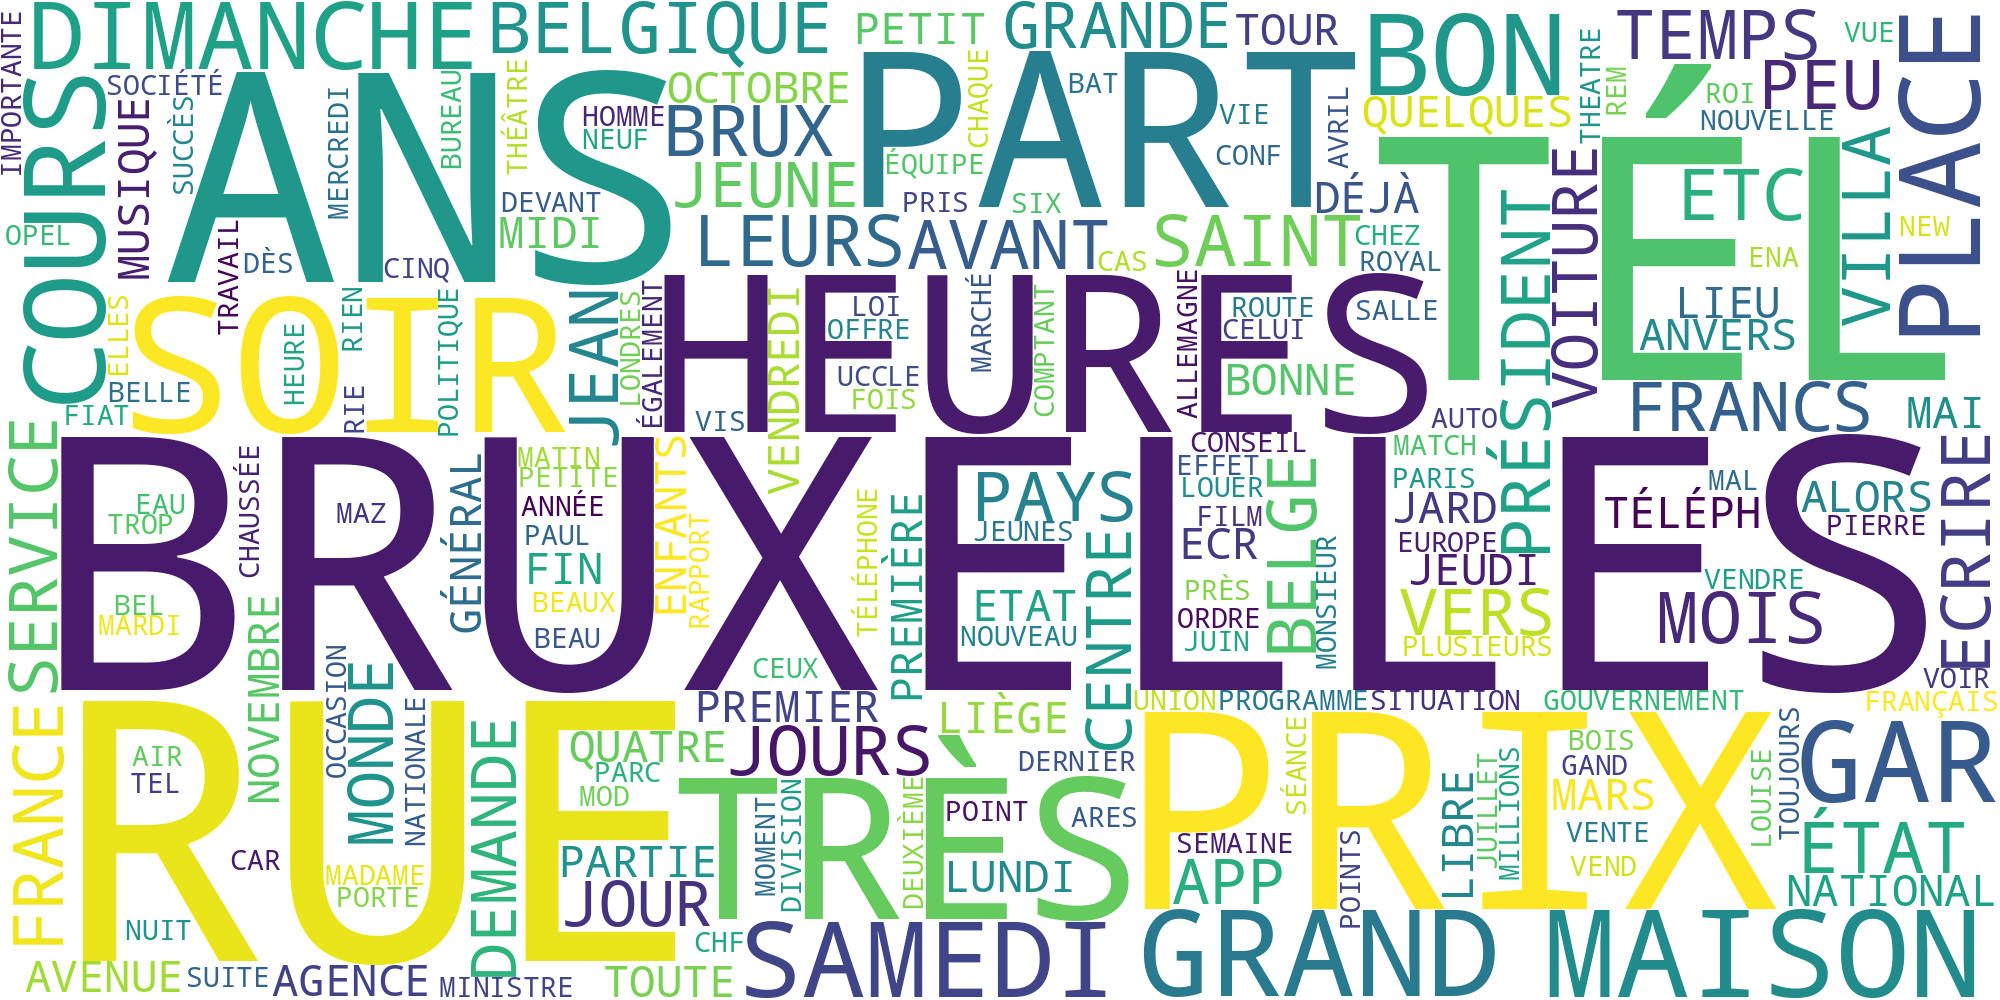

In [32]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Nuage de mots enrichi, année 1964

**Objectif** : faire ressortir les thèmes de l'année 1964

**Point de départ** : le premier nuage, obtenu après avoir retiré les stopwords de base. Il est dominé par des mots qui reviennent souvent mais ne décrivent pas l'année : TÉL, PRIX, SAMEDI, ANS, etc

**Ce que nous changeons** : au lieu de compter les occurrences d'un mot, nous comptons le nombre de journaux où il apparaît au moins une fois. Un mot qui revient dix fois dans un même journal ne compte donc que pour un. Nous retirons ensuite les mots inutiles, en notant la raison de chaque retrait.

**Plan en 4 étapes**  :

1. Compter, pour chaque mot, le nombre de journaux où il apparaît
2. Retirer les mots inutiles, avec une raison pour chacun
3. Générer le nuage de mots
4. Conclure à partir du nuage

### Étape 1 

In [34]:
import matplotlib.pyplot as plt

In [35]:
# On crée un compteur vide : pour chaque mot, il notera le nombre de journaux
presence = Counter()

# On parcourt chaque journal de l'année
for txt in txts:
    # On ouvre le journal et on lit son contenu
    with open(os.path.join(txt_path, txt), "r", encoding="utf-8") as f:
        contenu = f.read()

    # On découpe le texte en mots, on garde les mots utiles, en majuscules
    # set() enlève les doublons : chaque mot n'est compté qu'une fois par journal
    mots_journal = set(
        w.upper()
        for w in nltk.wordpunct_tokenize(contenu)
        if len(w) > 2 and w.isalpha() and w.lower() not in sw
    )

    # On ajoute 1 au compteur de chaque mot trouvé dans ce journal
    presence.update(mots_journal)


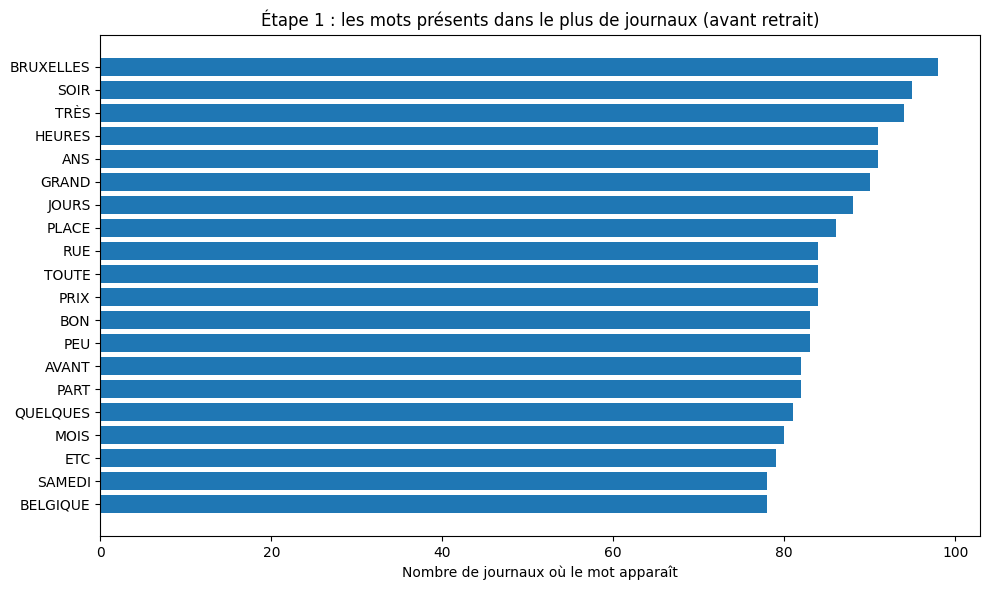

In [36]:
# Fonction qui affiche un graphique en barres des mots les plus présents
def graphique(donnees, titre, n=20):
    top = donnees.most_common(n)
    mots = [m for m, _ in top]
    valeurs = [v for _, v in top]
    plt.figure(figsize=(10, 6))
    plt.barh(mots[::-1], valeurs[::-1])   # inversé pour que le premier soit en haut
    plt.xlabel("Nombre de journaux où le mot apparaît")
    plt.title(titre)
    plt.tight_layout()
    plt.show()

graphique(presence, "Étape 1 : les mots présents dans le plus de journaux (avant retrait)")